In [11]:
# Import required libraries
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
# Create dataset using Pandas DataFrame
data = pd.DataFrame({
    'VAR1': [1.713, 0.180, 0.353, 0.940, 1.486,
             1.266, 1.540, 0.459, 0.773],

    'VAR2': [1.586, 1.786, 1.240, 1.566, 0.759,
             1.106, 0.419, 1.799, 0.186],

    'CLASS': [0, 1, 1, 0, 1, 0, 1, 1, 1]
})

# Separate features and class labels
X = data[['VAR1', 'VAR2']]
y = data['CLASS']


In [9]:
# Apply K-Means clustering with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

In [16]:
kmeans.fit(X)

c:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, n_init=10, random_state=42)

In [17]:
# Get cluster assignments
data['CLUSTER'] = kmeans.labels_

# Display cluster information
print("Cluster Assignments:")
print(data)

# Display centroids
print("\nCentroids:")
print(kmeans.cluster_centers_)

Cluster Assignments:
    VAR1   VAR2  CLASS  CLUSTER
0  1.713  1.586      0        2
1  0.180  1.786      1        0
2  0.353  1.240      1        0
3  0.940  1.566      0        2
4  1.486  0.759      1        1
5  1.266  1.106      0        2
6  1.540  0.419      1        1
7  0.459  1.799      1        0
8  0.773  0.186      1        1

Centroids:
[[0.33066667 1.60833333]
 [1.26633333 0.45466667]
 [1.30633333 1.41933333]]


In [18]:
# New data point
new_point = pd.DataFrame({
    'VAR1': [0.906],
    'VAR2': [0.606]
})

# Predict cluster for new point
predicted_cluster = kmeans.predict(new_point)

In [ ]:
# Assign class based on majority voting


# finding majority value of class for each cluster, majority value will be assign to cluster
cluster_classes = {}

for i in range(3):
    cluster_data = data[data['CLUSTER'] == i]

    cluster_classes[i] = cluster_data['CLASS'].mode()[0]    # [0] --> first mode value
    

In [20]:
# Predict final class
predicted_class = cluster_classes[predicted_cluster[0]]

# Display prediction
print("\nPredicted Cluster:", predicted_cluster[0])
print("Predicted Class:", predicted_class)



Predicted Cluster: 1
Predicted Class: 1


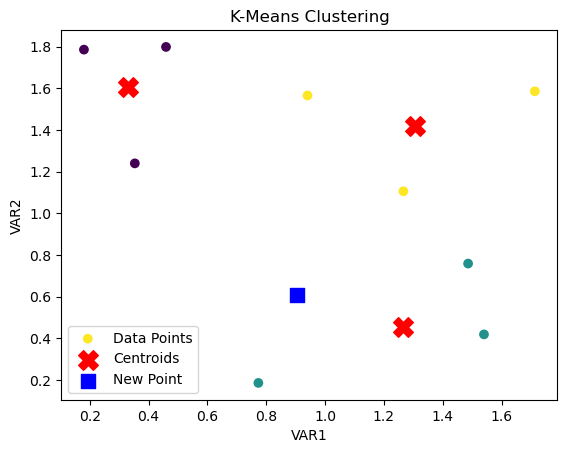

In [ ]:
# Visualize clusters
plt.scatter(X['VAR1'], X['VAR2'],
            c=kmeans.labels_, cmap='viridis',    # c --> It assigns colors to data points based on their cluster numbers.
            label='Data Points')

# Plot centroids
plt.scatter(kmeans.cluster_centers_[:, 0],    # kmeans.cluster_centers_  --> This returns the coordinates of all 3 centroids.
            kmeans.cluster_centers_[:, 1],
            color='red', marker='X', s=200,
            label='Centroids')

#Plot new point
plt.scatter(0.906, 0.606,
            color='blue', marker='s', s=100,
            label='New Point')

plt.xlabel('VAR1')
plt.ylabel('VAR2')
plt.title('K-Means Clustering')
plt.legend()
plt.show()